# MMA3001 Individual Project

## Predictive Maintenance using the AI4I 2020 Dataset

### Stage 1 — Dataset Audit

This notebook performs an initial audit of the AI4I 2020 Predictive Maintenance dataset before predictive modelling is undertaken.

The objectives are to:

- verify the dataset structure and dimensions;
- inspect variable names, data types and engineering units;
- identify missing values and duplicate observations;
- examine the operating ranges of numerical variables;
- inspect categorical variables and identifiers;
- quantify the machine-failure class distribution;
- identify potential sources of target leakage; and
- define a defensible set of candidate predictor variables.

No predictive models are trained during this stage.

In [43]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Display all dataframe columns when inspecting tables.
pd.set_option("display.max_columns", None)

# ---------------------------------------------------------
# Project configuration
# ---------------------------------------------------------

TARGET = "Machine failure"

FAILURE_MODE_COLS = [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF",
]

CANDIDATE_FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

# ---------------------------------------------------------
# Locate the repository root
# ---------------------------------------------------------
# This allows the notebook to work whether the current
# working directory is the repository root or /notebooks.

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    if (PROJECT_ROOT.parent / "data").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}"
    )

# ---------------------------------------------------------
# Load dataset
# ---------------------------------------------------------

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

display(df.head())

Dataset loaded successfully.
Rows: 10,000
Columns: 14


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [44]:
# ---------------------------------------------------------
# Dataset structure
# ---------------------------------------------------------

schema_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notna().sum(),
    "Unique Values": df.nunique(),
})

display(schema_summary)

# ---------------------------------------------------------
# Data-quality checks
# ---------------------------------------------------------

total_missing = int(df.isna().sum().sum())

duplicate_count = int(df.duplicated().sum())
duplicate_percentage = (
    100 * duplicate_count / len(df)
)

print(f"Total missing values: {total_missing:,}")
print(f"Duplicate rows: {duplicate_count:,}")
print(
    f"Duplicate percentage: "
    f"{duplicate_percentage:.3f}%"
)

# Show the affected columns only if missing data exists.
if total_missing > 0:
    missing_summary = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing (%)": df.isna().mean() * 100,
    })

    display(
        missing_summary[
            missing_summary["Missing Count"] > 0
        ]
    )

,Data Type,Non-Null Count,Unique Values
UDI,int64,10000,10000
Product ID,str,10000,10000
Type,str,10000,3
Air temperature [K],float64,10000,93
Process temperature [K],float64,10000,82
Rotational speed [rpm],int64,10000,941
Torque [Nm],float64,10000,577
Tool wear [min],int64,10000,246
Machine failure,int64,10000,2
TWF,int64,10000,2


Total missing values: 0
Duplicate rows: 0
Duplicate percentage: 0.000%


In [45]:
## Engineering Variable Audit

"""The available variables are examined to establish the operating domain represented by the dataset and determine whether categorical or identifier variables are suitable for predictive modelling."""

'The available variables are examined to establish the operating domain represented by the dataset and determine whether categorical or identifier variables are suitable for predictive modelling.'

In [46]:
# ---------------------------------------------------------
# Numerical engineering operating ranges
# ---------------------------------------------------------

engineering_numeric_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

range_summary = (
    df[engineering_numeric_cols]
    .agg(["min", "max", "mean", "std"])
    .T
    .rename(columns={
        "min": "Minimum",
        "max": "Maximum",
        "mean": "Mean",
        "std": "Std. Dev.",
    })
)

print("Numerical operating ranges:")
display(range_summary.round(3))


# ---------------------------------------------------------
# Product type distribution
# ---------------------------------------------------------

type_summary = pd.DataFrame({
    "Count": df["Type"].value_counts(),
    "Percentage (%)": (
        df["Type"].value_counts(normalize=True)
        * 100
    ),
})

print("\nProduct type distribution:")
display(type_summary.round(2))


# ---------------------------------------------------------
# Identifier uniqueness
# ---------------------------------------------------------

identifier_summary = pd.DataFrame({
    "Unique Values": [
        df["UDI"].nunique(),
        df["Product ID"].nunique(),
    ],
    "Total Rows": [
        len(df),
        len(df),
    ],
}, index=["UDI", "Product ID"])

identifier_summary["Uniqueness (%)"] = (
    identifier_summary["Unique Values"]
    / identifier_summary["Total Rows"]
    * 100
)

print("\nIdentifier assessment:")
display(identifier_summary.round(2))

Numerical operating ranges:


,Minimum,Maximum,Mean,Std. Dev.
Air temperature [K],295.3,304.5,300.005,2.000
Process temperature [K],305.7,313.8,310.006,1.484
Rotational speed [rpm],1168.0,2886.0,1538.776,179.284
Torque [Nm],3.8,76.6,39.987,9.969
Tool wear [min],0.0,253.0,107.951,63.654



Product type distribution:


,Count,Percentage (%)
Type,,
L,6000,60.00
M,2997,29.97
H,1003,10.03



Identifier assessment:


,Unique Values,Total Rows,Uniqueness (%)
UDI,10000,10000,100.0
Product ID,10000,10000,100.0


In [47]:
## Target Distribution and Class Imbalance

"""The prediction target is examined before modelling because severe class imbalance can make overall accuracy misleading. A model may achieve high accuracy simply by predicting the majority class while failing to detect machine failures."""

'The prediction target is examined before modelling because severe class imbalance can make overall accuracy misleading. A model may achieve high accuracy simply by predicting the majority class while failing to detect machine failures.'

,Count,Percentage (%)
Machine failure,,
0,9661,96.61
1,339,3.39


Observed machine failure rate: 3.39%
Majority-class baseline accuracy: 96.61%


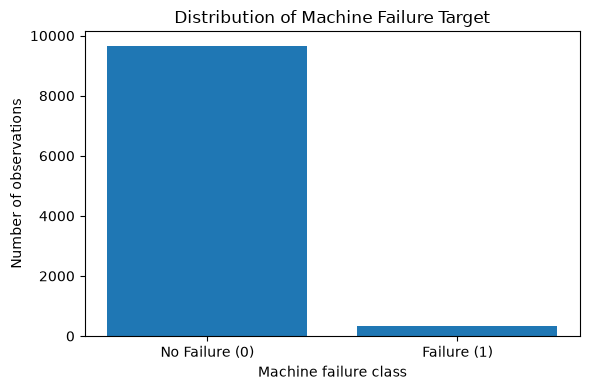


Recorded failure-mode counts:


,Failure Count
TWF,46
HDF,115
PWF,95
OSF,98
RNF,19



Relationship between failure modes and target:


Any recorded failure mode,0,1
Machine failure,,
0,9643,18
1,9,330


Machine-failure cases: 339
Failure cases with at least one recorded failure mode: 330
Failure-mode coverage of failure cases: 97.35%


In [48]:
# ---------------------------------------------------------
# Target class distribution
# ---------------------------------------------------------

target_counts = (
    df[TARGET]
    .value_counts()
    .sort_index()
)

target_percentages = (
    df[TARGET]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages,
})

display(target_summary.round(2))


# ---------------------------------------------------------
# Failure prevalence
# ---------------------------------------------------------

failure_rate = (
    df[TARGET].mean() * 100
)

print(
    f"Observed machine failure rate: "
    f"{failure_rate:.2f}%"
)


# ---------------------------------------------------------
# Majority-class baseline
# ---------------------------------------------------------
# This represents the accuracy obtained by predicting
# "no failure" for every observation.

majority_class_accuracy = (
    target_counts.max()
    / target_counts.sum()
)

print(
    f"Majority-class baseline accuracy: "
    f"{majority_class_accuracy * 100:.2f}%"
)


# ---------------------------------------------------------
# Target distribution plot
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(
    ["No Failure (0)", "Failure (1)"],
    target_counts.values,
)

ax.set_title(
    "Distribution of Machine Failure Target"
)
ax.set_xlabel("Machine failure class")
ax.set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Failure-mode indicators
# ---------------------------------------------------------

failure_mode_summary = pd.DataFrame({
    "Failure Count":
        df[FAILURE_MODE_COLS].sum()
})

print("\nRecorded failure-mode counts:")
display(failure_mode_summary)


# ---------------------------------------------------------
# Relationship between failure modes and target
# ---------------------------------------------------------
# Create an audit-only indicator showing whether at least
# one recorded failure mode is present in each observation.

any_failure_mode = (
    df[FAILURE_MODE_COLS]
    .sum(axis=1)
    .gt(0)
    .astype(int)
)

consistency_table = pd.crosstab(
    df[TARGET],
    any_failure_mode,
    rownames=[TARGET],
    colnames=["Any recorded failure mode"],
)

print("\nRelationship between failure modes and target:")
display(consistency_table)


# ---------------------------------------------------------
# Quantify association with machine failure
# ---------------------------------------------------------

failure_cases = int(
    (df[TARGET] == 1).sum()
)

failure_cases_with_mode = int(
    (
        (df[TARGET] == 1)
        & (any_failure_mode == 1)
    ).sum()
)

failure_mode_coverage = (
    100
    * failure_cases_with_mode
    / failure_cases
)

print(
    f"Machine-failure cases: "
    f"{failure_cases:,}"
)

print(
    "Failure cases with at least one recorded "
    f"failure mode: {failure_cases_with_mode:,}"
)

print(
    f"Failure-mode coverage of failure cases: "
    f"{failure_mode_coverage:.2f}%"
)

In [49]:
## 5. Categorical Variables and Identifiers

"""Categorical variables and identifiers are examined separately because identifiers should not automatically be treated as predictive features."""
type_summary = pd.DataFrame({
    "Count": df["Type"].value_counts(),
    "Percentage (%)": (
        df["Type"].value_counts(normalize=True) * 100
    ),
})

display(type_summary)

identifier_summary = pd.DataFrame({
    "Unique Values": [
        df["UDI"].nunique(),
        df["Product ID"].nunique(),
    ],
    "Total Rows": [
        len(df),
        len(df),
    ],
}, index=["UDI", "Product ID"])

identifier_summary["Uniqueness (%)"] = (
    identifier_summary["Unique Values"]
    / identifier_summary["Total Rows"]
    * 100
)

display(identifier_summary)

,Count,Percentage (%)
Type,,
L,6000,60.00
M,2997,29.97
H,1003,10.03


,Unique Values,Total Rows,Uniqueness (%)
UDI,10000,10000,100.0
Product ID,10000,10000,100.0


In [50]:
## Target Distribution and Class Imbalance

"""The prediction target is examined before modelling because severe class imbalance can make overall accuracy misleading. A model may achieve high accuracy simply by predicting the majority class while failing to detect machine failures."""

'The prediction target is examined before modelling because severe class imbalance can make overall accuracy misleading. A model may achieve high accuracy simply by predicting the majority class while failing to detect machine failures.'

,Count,Percentage (%)
Machine failure,,
0,9661,96.61
1,339,3.39


Observed machine failure rate: 3.39%
Majority-class baseline accuracy: 96.61%


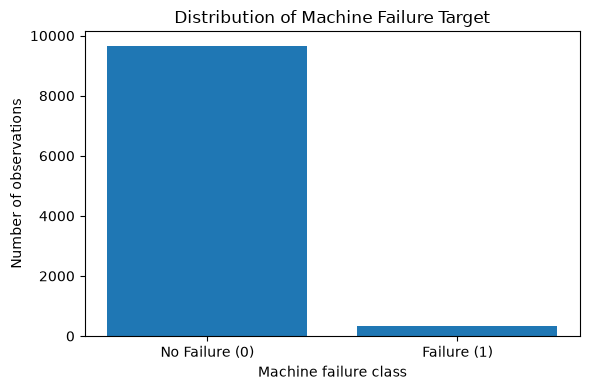


Recorded failure-mode counts:


,Failure Count
TWF,46
HDF,115
PWF,95
OSF,98
RNF,19



Relationship between failure modes and target:


Any recorded failure mode,0,1
Machine failure,,
0,9643,18
1,9,330


Machine-failure cases: 339
Failure cases with at least one recorded failure mode: 330
Failure-mode coverage of failure cases: 97.35%


In [51]:
# ---------------------------------------------------------
# Target class distribution
# ---------------------------------------------------------

target_counts = (
    df[TARGET]
    .value_counts()
    .sort_index()
)

target_percentages = (
    df[TARGET]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages,
})

display(target_summary.round(2))


# ---------------------------------------------------------
# Failure prevalence
# ---------------------------------------------------------

failure_rate = (
    df[TARGET].mean() * 100
)

print(
    f"Observed machine failure rate: "
    f"{failure_rate:.2f}%"
)


# ---------------------------------------------------------
# Majority-class baseline
# ---------------------------------------------------------
# This represents the accuracy obtained by predicting
# "no failure" for every observation.

majority_class_accuracy = (
    target_counts.max()
    / target_counts.sum()
)

print(
    f"Majority-class baseline accuracy: "
    f"{majority_class_accuracy * 100:.2f}%"
)


# ---------------------------------------------------------
# Target distribution plot
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(
    ["No Failure (0)", "Failure (1)"],
    target_counts.values,
)

ax.set_title(
    "Distribution of Machine Failure Target"
)
ax.set_xlabel("Machine failure class")
ax.set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Failure-mode indicators
# ---------------------------------------------------------

failure_mode_summary = pd.DataFrame({
    "Failure Count":
        df[FAILURE_MODE_COLS].sum()
})

print("\nRecorded failure-mode counts:")
display(failure_mode_summary)


# ---------------------------------------------------------
# Relationship between failure modes and target
# ---------------------------------------------------------
# Create an audit-only indicator showing whether at least
# one recorded failure mode is present in each observation.

any_failure_mode = (
    df[FAILURE_MODE_COLS]
    .sum(axis=1)
    .gt(0)
    .astype(int)
)

consistency_table = pd.crosstab(
    df[TARGET],
    any_failure_mode,
    rownames=[TARGET],
    colnames=["Any recorded failure mode"],
)

print("\nRelationship between failure modes and target:")
display(consistency_table)


# ---------------------------------------------------------
# Quantify association with machine failure
# ---------------------------------------------------------

failure_cases = int(
    (df[TARGET] == 1).sum()
)

failure_cases_with_mode = int(
    (
        (df[TARGET] == 1)
        & (any_failure_mode == 1)
    ).sum()
)

failure_mode_coverage = (
    100
    * failure_cases_with_mode
    / failure_cases
)

print(
    f"Machine-failure cases: "
    f"{failure_cases:,}"
)

print(
    "Failure cases with at least one recorded "
    f"failure mode: {failure_cases_with_mode:,}"
)

print(
    f"Failure-mode coverage of failure cases: "
    f"{failure_mode_coverage:.2f}%"
)